## CMF-BO-GP 6.1

### Function 6 - Cake Recipe

You’re optimising a cake recipe using a black-box function with five ingredient inputs, for example flour, sugar, eggs, butter and milk. Each recipe is evaluated with a combined score based on flavour, consistency, calories, waste and cost, where each factor contributes negative points as judged by an expert taster. This means the total score is negative by design. 
To frame this as a maximisation problem, your goal is to bring that score as close to zero as possible or, equivalently, to maximise the negative of the total sum.


### Components to the model
#### 1. Import libraries
#### 2. Import and Analyse data - combining baseline data with new queries; then performing statistical analysis on the combined data
#### 3. Visualising data - create a 2D view with showing baseline, additional queries and current maxima - and a 3D representation.
#### 4. Core Model - v1 - UCB / EI models - with length scales and bounds
#### 5. Expliotation model - for final queries to maximise outputs (from scipy.optimize import minimize)

In [2]:
# ==============================================
# 1. Import required libraries to support model
# ==============================================

import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from IPython.display import clear_output
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from scipy.stats import norm
from scipy.interpolate import griddata

In [3]:
# ====================================
# 2. Import and Analyse the data set  
# ====================================

# 1. Load 5D spatial coordinate data and output values
inputs = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC6/initial_inputs.npy')
output = np.load('/home/mcevoyj777/_CAPSTONE/Models/FUNC6/initial_outputs.npy')

print(f"Base Maximia: ",output.max())

extra_inputs = [[0.424516, 0.367334, 0.467170, 0.746827, 0.158948],[0.188862, 0.514438, 0.083176, 0.938769, 0.000001],
                [0.892895, 0.772634, 0.937451, 0.406290, 0.360158],[0.427487, 0.295840, 0.570672, 0.780035, 0.190551],
                [0.370791, 0.175107, 0.656395, 0.940692, 0.236384],[0.479940, 0.323820, 0.646369, 0.734312, 0.264380],
                [0.332131, 0.283475, 0.973347, 0.723901, 0.193395],[0.000000, 0.317806, 0.626706, 0.907558, 0.167783],
                [0.419950, 0.285695, 0.615926, 0.791806, 0.000001],[0.363605, 0.256815, 0.591349, 0.685226, 0.141890],
                [0.455932, 0.308242, 0.599215, 0.912231, 0.150137]]
extra_output = [-0.33663026414694064,-1.2679820129946602,-1.7016255198269483,
                -0.16260391178773215,-0.5210499647366378,-0.27987100150491395,
               -0.6279802117175647,-0.6535354094291767,-0.2670654106403355,
               -0.3150368931959659,	-0.27907093553703366]

inputs = np.vstack([inputs, extra_inputs])
output = np.append(output, extra_output)

print(f"Current Maxima: ",output.max())

np.set_printoptions(precision=9, suppress=True)


# 2. Combine into a single Pandas DataFrame
df = pd.DataFrame(inputs, columns=['Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'])
df['Output_Target'] = output

# 3. Compute the correlation matrix
# Change method to 'spearman' if relationships ar8e non-linear curves
corr_matrix = df.corr(method='pearson')

# 4. Isolate how each input correlates *only* with the target output
target_corr = corr_matrix['Output_Target'].drop('Output_Target')

print("Correlation with Output:")
print(target_corr)

# Calculate non-linear relationship dependency (higher score = stronger relationship)
mi_scores = mutual_info_regression(inputs, output)

for name, score in zip(['Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], mi_scores):
    print(f"{name} Mutual Information Score: {score:.4f}")

# Fit a quick non-linear model that checks all 4 dimensions simultaneously
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(inputs, output)

# Extract total feature importances (including interactions)
importances = model.feature_importances_

for name, score in zip(['Input_V','Input_W','Input_X', 'Input_Y', 'Input_Z'], importances):
    print(f"{name} Total Importance (with interactions): {score:.4f}")

Base Maximia:  -0.7142649478202404
Current Maxima:  -0.16260391178773215
Correlation with Output:
Input_V   -0.194897
Input_W   -0.560649
Input_X    0.284955
Input_Y    0.620004
Input_Z   -0.627078
Name: Output_Target, dtype: float64
Input_V Mutual Information Score: 0.2489
Input_W Mutual Information Score: 0.3107
Input_X Mutual Information Score: 0.1628
Input_Y Mutual Information Score: 0.1831
Input_Z Mutual Information Score: 0.2728
Input_V Total Importance (with interactions): 0.0911
Input_W Total Importance (with interactions): 0.1655
Input_X Total Importance (with interactions): 0.0579
Input_Y Total Importance (with interactions): 0.4724
Input_Z Total Importance (with interactions): 0.2132


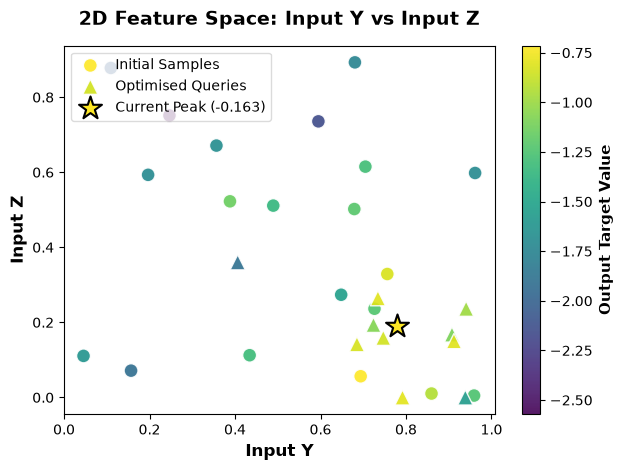

In [4]:
# ===================================
# 3.1 Visualise the data set Y and Z
# ===================================

# Find the coordinates of the maximum value dynamically
max_row_index = df['Output_Target'].idxmax()
max_y = df.loc[max_row_index, 'Input_Y']
max_z = df.loc[max_row_index, 'Input_Z']
max_val = df.loc[max_row_index, 'Output_Target']



# Create scatter plot with the first 30 smaples
scatter1 = plt.scatter(
    data=df.iloc[:20], 
    x='Input_Y', 
    y='Input_Z',
    c='Output_Target', 
    cmap='viridis', 
    s=100,            # Marker size
    edgecolor='w',    # White border around markers
    alpha=0.9
)

# Plot the next query samples (e.g., as triangles '^')
scatter2 = plt.scatter(
    data=df.iloc[20:len(output)], 
    x='Input_Y', 
    y='Input_Z', 
    c='Output_Target', 
    cmap='viridis', 
    s=120,            # Made slightly larger so triangles stand out nicely
    edgecolor='w',    
    alpha=0.9,
    marker='^',       # <--- Shape for the next 9 points
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max()
)

scatter3 = plt.scatter(
    x=max_y, 
    y=max_z, 
    c=[max_val],   
    cmap='viridis',    # Highly visible contrasting color
    vmin=df['Output_Target'].min(),
    vmax=df['Output_Target'].max(),
    s=300,            # Much larger marker size to make it pop
    marker='*',       # Star shape
    edgecolor='black',
    linewidth=1.5,
    label=f'Current Max ({max_val:.2f})',
    zorder=5          # Ensures it sits on top of all other points
)


# Add elements
cbar = plt.colorbar(scatter1)
cbar.set_label('Output Target Value', fontsize=11, fontweight='bold')
plt.xlabel('Input Y', fontsize=12, fontweight='bold')
plt.ylabel('Input Z', fontsize=12, fontweight='bold')
plt.title('2D Feature Space: Input Y vs Input Z', fontsize=14, fontweight='bold', pad=15)

plt.legend(
    handles=[scatter1, scatter2,scatter3], 
    labels=['Initial Samples', 'Optimised Queries', f'Current Peak ({max_val:.3f})'],
    loc='upper left', 
    frameon=True, 
    facecolor='white', 
    edgecolor='lightgray', 
    fontsize=10
)
plt.tight_layout()
plt.show()

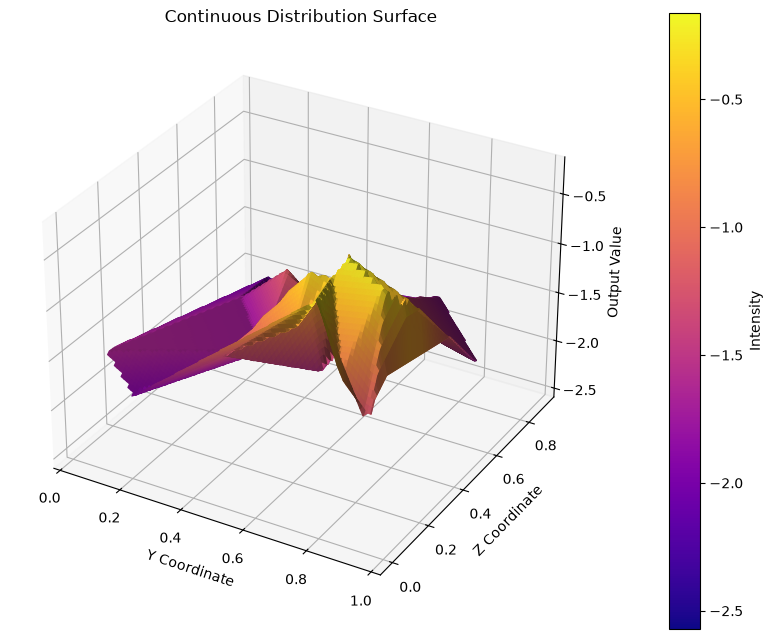

In [5]:
# ===================================
# 3.2. Visualise the data set 3D
# ===================================

coords = (inputs[:,3],inputs[:,4])

# 1. Define a regular 2D grid based on your data boundaries
grid_x, grid_y = np.meshgrid(
    np.linspace(coords[0].min(), coords[0].max(), 100),
    np.linspace(coords[1].min(), coords[1].max(), 100)
)

# 2. Interpolate the scattered (x, y, z) data onto the uniform grid
# Options for method: 'linear', 'cubic', or 'nearest'
grid_z = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# If your y_clean variable is different from values, interpolate it too for the colors
grid_color = griddata((coords[0], coords[1]), output, (grid_x, grid_y), method='linear')

# 3. Create the 3D surface plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

norm = colors.Normalize(vmin=output.min(), vmax=output.max())

# Plot the continuous surface
# facecolors overrides standard mapping to use your output
surf = ax.plot_surface(
    grid_x, grid_y, grid_z,
    facecolors=plt.cm.plasma(norm(grid_color)),
    rcount=100, ccount=100,  # Grid resolution
    antialiased=True,
    shade=True
)

# 4. Design elements
# Create a dummy scalar mappable object just to display the colorbar correctly
mappable = plt.cm.ScalarMappable(cmap='plasma', norm = colors.Normalize(vmin=output.min(), vmax=output.max()))
fig.colorbar(mappable, ax=ax, label="Intensity", pad=0.1)

ax.set_xlabel("Y Coordinate")
ax.set_ylabel("Z Coordinate")
ax.set_zlabel("Output Value")

ax.set_title("Continuous Distribution Surface")

plt.show()

In [6]:
# ===========================================
# 4 (v1) GP Model - with UCB/EI 
# ===========================================

import numpy as np
from sklearn.ensemble import RandomForestRegressor

# Train a predictive model on your 20 existing samples
predictor = RandomForestRegressor(n_estimators=100, random_state=42)
predictor.fit(inputs, output)

def objective_5d(X):
    """
    Surrogate function for 5D optimization.
    X: A 2D numpy array of shape (n_samples, 5) sent by the optimizer.
    """
    # Force input to be 2D array matrix for sklearn compatibility
    X = np.atleast_2d(X)
    
    # Predict the output value using the trained model
    predictions = predictor.predict(X)
    
    # Return as a flat 1D array as expected by your code (.ravel())
    print(f"Prediction {predictions}")
    return predictions.ravel()

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, ConstantKernel as C
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

def upper_confidence_bound(mu, sigma, kappa=0.1):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

In [5]:
def bayesian_optimization_nd(objective_func, n_dims, n_iterations=1, 
                            n_initial=1, acquisition='ei'):
    """
    Bayesian Optimization for n-dimensional functions.
    Assumes bounds [0, 1] for all dimensions.
    """
    bounds = [(0, 1) for _ in range(n_dims)]
    
    # Initialize
    X_samples = inputs
    y_samples = output

    #Define initial length scales based on your feature importance.
    # Lower value = High sensitivity/importance (Model pays close attention to tiny movements)
    # Higher value = Low sensitivity/passenger (Model assumes changes have very little local impact)
    initial_length_scales = np.array([
        0.5,  # Input_V (Moderate interaction)
        0.2,  # Input_W (High negative correlation)
        1.0,  # Input_X (The passenger - highly smoothed out)
        0.1,  # Input_Y (The major driver - hyper-sensitive tracking)
        0.1   # Input_Z (Strongest penalty trap)
    ])
    length_scale_bounds = [(1e-2, 1e2) for _ in range(n_dims)]
    
    best_values = [y_samples.max()]
    
    print(f"Starting {n_dims}D optimization with {n_initial} initial samples...")
    print(f"Initial best: {y_samples.max():.4f}\n")
  
    
    for iteration in range(n_iterations):
        # Fit GP
        ard_kernel = C(1.0, (1e-3, 1e3)) * Matern(
            length_scale=initial_length_scales, 
            length_scale_bounds=length_scale_bounds, 
            nu=2.5  # nu=2.5 enforces Matérn 5/2 behavior
            )
        gp = GaussianProcessRegressor(kernel=ard_kernel, alpha=1e-6,normalize_y=True,
                                     n_restarts_optimizer=10)
        gp.fit(X_samples, y_samples)

        # Optimize acquisition function
        def acq_objective(X):
            X = X.reshape(1, -1)
            mu, sigma = gp.predict(X, return_std=True)
            
            if acquisition == 'ei':
                acq_val = expected_improvement(mu, sigma, y_samples.max(),xi=0.0)
            else:
                acq_val = upper_confidence_bound(mu, sigma, kappa=0.2)
           
            return -acq_val
        
        # Multi-start optimization
        best_acq = np.inf
      
        X_next = None
        
        for _ in range(100):  # More starts for higher dimensions
            x0 = np.random.uniform(0, 1, n_dims)
            result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
            if result.fun < best_acq:
                best_acq = result.fun
                X_next = result.x
                print(f"Optimized Next Point Found! Predicted Acquisition Score: {-best_acq:.6f}")
                print(f"Coordinates to test next: {X_next}")

       
        # Evaluate
        y_next = objective_func(X_next.reshape(1, -1)).ravel()
        
        # Update
        X_samples = np.vstack([X_samples, X_next])
        y_samples = np.append(y_samples, y_next)
        best_values.append(y_samples.max())
        
        if (iteration + 1) % 10 == 0:
            print(f"Iteration {iteration + 1}: Best f(x)={y_samples.max():.4f}")
    
        return X_samples, y_samples, best_values



# Run 6D optimization
X_samples_5d, y_samples_5d, best_values_5d = bayesian_optimization_nd(
    objective_5d, 
    n_dims=5,
    n_iterations=50,
    n_initial=1,
    acquisition='ei'
)

Starting 5D optimization with 1 initial samples...
Initial best: -0.1626

Optimized Next Point Found! Predicted Acquisition Score: 0.002569
Coordinates to test next: [1. 0. 1. 0. 1.]
Optimized Next Point Found! Predicted Acquisition Score: 0.003102
Coordinates to test next: [0. 1. 1. 1. 1.]
Optimized Next Point Found! Predicted Acquisition Score: 0.010885
Coordinates to test next: [0.384819801 0.299247873 0.603199326 0.809731507 0.188474412]
Optimized Next Point Found! Predicted Acquisition Score: 0.010885
Coordinates to test next: [0.384820878 0.299250176 0.603200358 0.809732766 0.188478128]
Optimized Next Point Found! Predicted Acquisition Score: 0.010885
Coordinates to test next: [0.384820262 0.29925043  0.603201036 0.809732462 0.188478839]
Prediction [-0.330030838]


In [7]:
# ============================================
# 5. Exploitation Model - scipy.optimize
# ============================================

## import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C
from scipy.optimize import minimize

# 1. Load the 5D dataset (Features: V, W, X, Y, Z)
X_train = inputs
y_train = output

# 2. Configure a Matern GP Surrogate Model
# Matern nu=1.5 allows for the distinct "cliffs"
kernel = C(1.0, (1e-3, 1e3)) * Matern(length_scale=np.ones(5), length_scale_bounds=(1e-2, 10.0), nu=1.5)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=25, alpha=1e-6, random_state=42)

# Fit model to historical space
gp.fit(X_train, y_train)

# 3. Formulate Optimization Target (Negative prediction for minimization algorithm)
def objective(x):
    # Predict returns shape (1, 5), flatten to extract scalar
    return -float(gp.predict(x.reshape(1, -1))[0])

# 4. Enforce Bounding Box System limits [0.0, 1.0]
bounds = [
    (0.30, 0.50),  # V
    (0.20, 0.30),  # W
    (0.50, 0.90),  # X
    (0.65, 0.95),  # Y
    (0.01, 0.35)   # Z
]

# Use your historical peak coordinate as the optimization warm-start point
x_start = np.array([0.427487, 0.295840, 0.570672, 0.780035, 0.190551])

# 5. Execute L-BFGS-B Optimization Local Search
result = minimize(objective, x_start, method='L-BFGS-B', bounds=bounds)

# 6. Display Predicted Coordinates
print("--- GAUSSIAN PROCESS TARGET PREDICTION ---")
print(f"Predicted Max Output: {abs(result.fun):.4f}")
print("Optimal Coordinates:")
for name, val in zip(['V', 'W', 'X', 'Y', 'Z'], result.x):
    print(f"  Input_{name}: {val:.6f}")

--- GAUSSIAN PROCESS TARGET PREDICTION ---
Predicted Max Output: 0.1595
Optimal Coordinates:
  Input_V: 0.425139
  Input_W: 0.295186
  Input_X: 0.579525
  Input_Y: 0.794344
  Input_Z: 0.183596
